In [1]:
import numpy as np
import os
import glob
import xarray as xr
from scipy import interpolate
from netCDF4 import Dataset
from datetime import datetime
import pandas as pd
import time
import matplotlib.pyplot as plt


data_dir = '/home/lukeew/Local_work/data/01_SLW_xgb'

amps_dir = data_dir + '/AMPS_NC/'
mpl2nc_dir = data_dir + '/CHCH_preprocessed/mpl2nc{}/'

alcf_dir = data_dir + '/CHCH_preprocessed/alcf{}/lidar/'

mpl_proc_dir = data_dir + '/CHCH_v4_reference/preprocessed{}/'

In [2]:
date = '20210518'

In [7]:
infile = mpl_proc_dir.format(date[:6]) + '/{}.nc'.format(date)
print('  <--- ' + infile)

ds = xr.open_dataset(infile, drop_variables = ['backscatter', 'temp', 'vdr', 'vdr_layer'])
ds

  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v4_reference/preprocessed202105//20210518.nc


<xarray.Dataset>
Dimensions:     (time: 288, height: 300)
Coordinates:
  * time        (time) datetime64[ns] 2021-05-18T00:02:29.999991 ... 2021-05-...
  * height      (height) float64 25.0 75.0 125.0 ... 1.492e+04 1.498e+04
Data variables:
    copol       (time, height) float64 ...
    crosspol    (time, height) float64 ...
    cloud_mask  (time, height) int8 ...

In [7]:
# amps_filepath= amps_dir+"{0}00/{0}00_WRF_NZ_f*.nc".format(date)
infiles = mpl_proc_dir.format('202106') + '/*.nc'
ds = xr.open_mfdataset(infiles,combine='nested',concat_dim='time',drop_variables=['temp', 'vdr_layer'])

In [22]:
x = [1,2,3,4,5,6,7,8,9,9]
a = [0,0,1,1,0,1,1,1,1,0]

cloud_mask = a

# layer_int(x, a)

cm_df = pd.Series(cloud_mask)
x_df = pd.Series(x)

layers_x_arr = np.full(len(cm_df[cm_df==1].groupby((cm_df==0).cumsum())), np.nan)  # array of length (n cloud layers)
heights_x_arr = np.full(np.shape(cloud_mask),np.nan)  # array of length (n altitude bins)

# print(len(cm_df[cm_df==1].groupby((cm_df==0).cumsum())))

# print((cm_df==0).cumsum())
idx = 0
for i,v in cm_df[cm_df==1].groupby((cm_df==0).cumsum()):
    x_layer_int = x_df[v.index].sum()
    layers_x_arr[idx] = x_layer_int
    heights_x_arr[v.index] = x_layer_int
    idx += 1

layers_x_arr,heights_x_arr

(array([ 7., 30.]), array([nan, nan,  7.,  7., nan, 30., 30., 30., 30., nan]))

In [8]:
def layer_int(x, cloud_mask):
    '''Function to calculate the layer integrated value of property x. 
    I.e. the sum across a group of consecutive cloud bins.
    Returns as a function of n_layer and as a function of altitude.'''
    
    cm_df = pd.Series(cloud_mask)
    x_df = pd.Series(x)

    layers_x_arr = np.full(len(cm_df[cm_df==1].groupby((cm_df==0).cumsum())), np.nan)  # array of length (n cloud layers)
    heights_x_arr = np.full(np.shape(cloud_mask),np.nan)  # array of length (n altitude bins)

    idx = 0
    for i,v in cm_df[cm_df==1].groupby((cm_df==0).cumsum()):
        x_layer_int = x_df[v.index].sum()
        layers_x_arr[idx] = x_layer_int
        heights_x_arr[v.index] = x_layer_int
        idx += 1

    return layers_x_arr, heights_x_arr


In [9]:
CALIBRATION_COEFF = 3.75e-6

copol = ds.copol * CALIBRATION_COEFF * 1000
crosspol = ds.crosspol * CALIBRATION_COEFF * 1000

backscatter = copol + crosspol

bs_layers_all = []
depol_ratio_layers_all = []

bs_heights_all = []
depol_ratio_heights_all = []

for time_idx, cm_profile in enumerate(ds.cloud_mask):
    copol_layers, copol_heights = layer_int(copol[time_idx].values, cm_profile.values)
    crosspol_layers, crosspol_heights = layer_int(crosspol[time_idx].values, cm_profile.values)
    bs_layers, bs_heights = layer_int(backscatter[time_idx].values, cm_profile.values)
    depol_ratio_layers = crosspol_layers/copol_layers
    depol_ratio_heights = crosspol_heights/copol_heights

    bs_layers_all.extend(bs_layers)
    depol_ratio_layers_all.extend(depol_ratio_layers)
    bs_heights_all.extend(bs_heights)
    depol_ratio_heights_all.extend(depol_ratio_heights)

In [4]:
ds.backscatter.values.flatten()

array([5.14008117e-07, 3.46462268e-06, 5.28636406e-06, ...,
       1.60137642e-06, 1.37722260e-06, 7.18858905e-07])

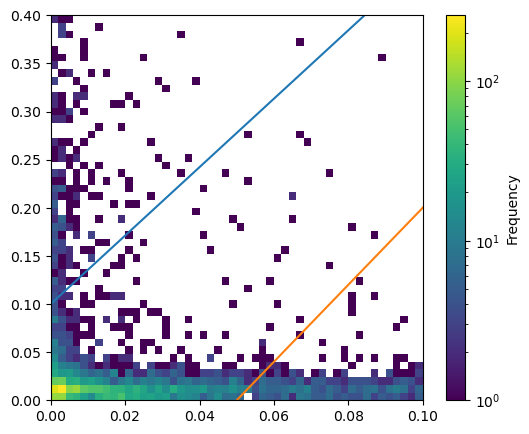

In [10]:
fig = plt.figure(figsize=(6,5))
ax = fig.subplots(1, 1)

norm = 'log'
ranges = [[0,0.1], [0,0.4]]

counts, xedges, yedges, im = ax.hist2d(bs_layers_all, depol_ratio_layers_all, bins=50, range=ranges,norm=norm)
# counts, xedges, yedges, im = ax.hist2d(ds.backscatter.values.flatten()*1000, ds.vdr.values.flatten(), bins=50, range=ranges,norm=norm)

fig.colorbar(im, ax=ax, label='Frequency')

# ax.set_xlabel('VDR')
# ax.set_ylabel('Temperature ($\degree$C)')

# ax.vlines([0.1, 0.4], ranges[1][0], ranges[1][1], colors='red',linestyles='dashed')
# ax.hlines(0, 0,1, colors='red',linestyles='dashed')

tt = np.linspace(0,1,1000)
y = 32*tt/9 + 0.1
y2 = 4*tt - 0.2

plt.plot(tt, y)
plt.plot(tt, y2)
